# Experiment 03_8 — Required Image Interpretability with Grad-CAM

**Project requirement:** Provide an interpretable analysis of the optimized image classifier from
experiment `03_7`. Grad-CAM is used to inspect two correct predictions, two representative errors
and one controlled comparison of the same image with and without smart white-border cropping.

The objective is to explain selected model decisions and identify practical limitations. This is a
qualitative interpretability analysis, not another model-training or performance-estimation step.

Grad-CAM weights the final feature maps with the spatially averaged gradient of a target-class
logit and applies ReLU to retain positive contributions:

$$L_{\mathrm{Grad-CAM}}^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right).$$

The maps are qualitative explanations, not causal proof of how the model reasons.

## 1. Configuration and reproducibility

In [1]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torchvision import transforms
from torchvision.models import convnext_tiny

# Reproducibility and validation contract shared with the modeling notebooks.
IN_COLAB                 = 'google.colab' in sys.modules
RANDOM_STATE             = 42
EXPECTED_VALIDATION_ROWS = 16_984

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Keep paths compatible with the local repository and the private Colab workspace.
if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    DRIVE_DIR      = Path('/content/drive/MyDrive/rakuten_colab')
    IMAGE_DIR      = DRIVE_DIR / 'images'
    MANIFEST_PATH  = DRIVE_DIR / 'image_split_clean.csv'
    CHECKPOINT_PATH = DRIVE_DIR / 'outputs/03_7_convnext_tiny_optimized_best.pt'
    PROJECT_ROOT   = None
else:
    PROJECT_ROOT = Path.cwd().resolve()
    while PROJECT_ROOT.name in {'03_image_fineTuning', 'notebooks'}:
        PROJECT_ROOT = PROJECT_ROOT.parent

    IMAGE_DIR       = PROJECT_ROOT / 'data/raw/images/image_train'
    MANIFEST_PATH   = PROJECT_ROOT / 'data/processed/image_split_clean.csv'
    CHECKPOINT_PATH = PROJECT_ROOT / 'models/outputs/03_7_convnext_tiny_optimized_best.pt'

    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

# Reuse the single inferred category-name table when the repository source is available.
try:
    from src.categories import CATEGORY_NAMES
except ModuleNotFoundError:
    CATEGORY_NAMES = {}


def category_name(code):
    return CATEGORY_NAMES.get(int(code), f'Class {int(code)}')


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Runtime     :', 'Google Colab' if IN_COLAB else 'Local workstation')
print('Device      :', device)
print('Manifest    :', MANIFEST_PATH)
print('Images      :', IMAGE_DIR)
print('Checkpoint  :', CHECKPOINT_PATH)

assert MANIFEST_PATH.exists(), f'Missing split manifest: {MANIFEST_PATH}'
assert IMAGE_DIR.exists(), f'Missing image directory: {IMAGE_DIR}'
assert CHECKPOINT_PATH.exists(), f'Missing model checkpoint: {CHECKPOINT_PATH}'

Runtime     : Local workstation
Device      : cpu
Manifest    : /Users/wahajaslam/capstone_raukaten/data/processed/image_split_clean.csv
Images      : /Users/wahajaslam/capstone_raukaten/data/raw/images/image_train
Checkpoint  : /Users/wahajaslam/capstone_raukaten/models/outputs/03_7_convnext_tiny_optimized_best.pt


## 2. Load the shared validation split and optimized image model

The unchanged shared validation split is reused so that every explanation refers to the same products
used for the final image-model evaluation. PyTorch `state_dict` checkpoints are portable between
Linux, macOS and Windows, while `map_location` handles CPU/GPU differences. A checkpoint that exists
but cannot be opened is normally incomplete or corrupted during copying; the operating system used
for training is not the cause.

In [2]:
manifest         = pd.read_csv(MANIFEST_PATH)
required_columns = {'row_id', 'imageid', 'productid', 'prdtypecode', 'split'}
assert required_columns.issubset(manifest.columns)
assert manifest['row_id'].is_unique

# Interpret exactly the same validation products used by image, text and fusion models.
validation = manifest.loc[manifest['split'].eq('validation')].copy().reset_index(drop=True)
assert len(validation) == EXPECTED_VALIDATION_ROWS

validation['filename'] = [
    f'image_{int(row.imageid)}_product_{int(row.productid)}.jpg'
    for row in validation.itertuples(index=False)
]
validation['image_path'] = validation['filename'].map(lambda name: IMAGE_DIR / name)
missing                  = ~validation['image_path'].map(Path.exists)
assert not missing.any(), f'Missing validation images: {int(missing.sum()):,}'

# Load the optimized 03_7 checkpoint and recreate its 27-class output layer.
try:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=False)
except Exception as exc:
    raise RuntimeError(
        'The checkpoint could not be loaded. PyTorch checkpoints are cross-platform; '
        're-copy the complete file from the training machine or Google Drive.'
    ) from exc

class_to_index = {int(code): int(index) for code, index in checkpoint['class_to_index'].items()}
index_to_class = {index: code for code, index in class_to_index.items()}
class_codes    = [index_to_class[index] for index in range(len(index_to_class))]

model               = convnext_tiny(weights=None)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, len(class_codes))
model.load_state_dict(checkpoint['model_state_dict'])
model               = model.to(device).eval()

print(f'Validation rows: {len(validation):,}')
print(f'Classes        : {len(class_codes)}')
print('Checkpoint metrics (single-view evaluation):')
for name, value in checkpoint.get('validation_metrics', {}).items():
    print(f'  {name:18s}: {float(value):.4f}')

Validation rows: 16,984
Classes        : 27
Checkpoint metrics (single-view evaluation):
  validation_loss   : 1.0953
  accuracy          : 0.7011
  weighted_f1       : 0.6980
  macro_f1          : 0.6719


## 3. Reproduce the `03_7` preprocessing and define Grad-CAM

In [3]:
# Reproduce the exact SmartWhiteBorderCrop parameters used in experiment 03_7.
WHITE_THRESHOLD = 245
CROP_PADDING     = 12
MAX_BBOX_RATIO  = 0.75
MIN_CROP_SIZE   = 224


class SmartWhiteBorderCrop:
    """Remove large white borders while preserving product resolution."""

    def __init__(
        self,
        threshold=WHITE_THRESHOLD,
        pad=CROP_PADDING,
        max_ratio=MAX_BBOX_RATIO,
        min_crop=MIN_CROP_SIZE,
    ):
        self.threshold = threshold
        self.pad       = pad
        self.max_ratio = max_ratio
        self.min_crop  = min_crop
        self.lut       = [255 if value < threshold else 0 for value in range(256)]

    def __call__(self, image):
        bbox = image.convert('L').point(self.lut).getbbox()
        if bbox is None:
            return image

        width, height = image.size
        bbox_width    = bbox[2] - bbox[0]
        bbox_height   = bbox[3] - bbox[1]
        bbox_ratio    = max(bbox_width / max(width, 1), bbox_height / max(height, 1))
        if bbox_ratio >= self.max_ratio:
            return image

        object_side = max(bbox_width, bbox_height) + 2 * self.pad
        side        = min(max(width, height), max(self.min_crop, object_side))
        center_x    = (bbox[0] + bbox[2]) // 2
        center_y    = (bbox[1] + bbox[3]) // 2
        left        = max(0, min(width - side, center_x - side // 2))
        top         = max(0, min(height - side, center_y - side // 2))
        return image.crop((left, top, left + side, top + side))

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

smart_display_transform = transforms.Compose([
    SmartWhiteBorderCrop(),
    transforms.Resize(236, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
])
smart_tensor_transform = transforms.Compose([
    smart_display_transform,
    transforms.ToTensor(),
    normalize,
])

# Control pipeline: identical resizing and normalization, but no white-border crop.
plain_display_transform = transforms.Compose([
    transforms.Resize(236, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
])
plain_tensor_transform = transforms.Compose([
    plain_display_transform,
    transforms.ToTensor(),
    normalize,
])

In [4]:
class ConvNeXtGradCAM:
    """Generate class-specific Grad-CAM maps from the final ConvNeXt feature stage."""

    def __init__(self, network, target_layer=None):
        self.network      = network
        self.target_layer = target_layer or network.features[7]
        self.activations  = None
        self.gradients    = None
        self.handles      = [
            self.target_layer.register_forward_hook(self._capture_activations),
            self.target_layer.register_full_backward_hook(self._capture_gradients),
        ]

    def _capture_activations(self, _module, _inputs, output):
        self.activations = output

    def _capture_gradients(self, _module, _grad_inputs, grad_outputs):
        self.gradients = grad_outputs[0]

    def generate(self, input_tensor, target_index=None):
        self.network.zero_grad(set_to_none=True)
        logits          = self.network(input_tensor)
        probabilities   = torch.softmax(logits, dim=1)[0]
        predicted_index = int(logits.argmax(dim=1).item())
        explained_index = predicted_index if target_index is None else int(target_index)

        logits[0, explained_index].backward()
        gradients   = self.gradients.detach()
        activations = self.activations.detach()
        weights     = gradients.mean(dim=(2, 3), keepdim=True)
        cam         = F.relu((weights * activations).sum(dim=1, keepdim=True))
        cam         = F.interpolate(
            cam,
            size=input_tensor.shape[2:],
            mode='bilinear',
            align_corners=False,
        ).squeeze().cpu().numpy()

        minimum, maximum = float(cam.min()), float(cam.max())
        cam = (
            (cam - minimum) / (maximum - minimum)
            if maximum > minimum
            else np.zeros_like(cam)
        )
        return cam, predicted_index, explained_index, probabilities.detach().cpu().numpy()

    def close(self):
        for handle in self.handles:
            handle.remove()

# Hook the trained model only after its checkpoint has been loaded.
gradcam = ConvNeXtGradCAM(model)

In [5]:
def overlay(display_image, cam, alpha=0.5):
    """Blend a normalized Grad-CAM map with its displayed model input."""
    image   = np.asarray(display_image, dtype=np.float32) / 255.0
    heatmap = plt.get_cmap('jet')(cam)[..., :3]
    return np.clip((1 - alpha) * image + alpha * heatmap, 0, 1)


def load_image(row):
    """Load one RGB product image referenced by a manifest row."""
    with Image.open(row.image_path) as image:
        return image.convert('RGB')


@torch.no_grad()
def predict_row(row, tensor_transform=smart_tensor_transform):
    """Return the predicted product code and its confidence for one row."""
    image           = load_image(row)
    tensor          = tensor_transform(image).unsqueeze(0).to(device)
    probabilities   = torch.softmax(model(tensor), dim=1)[0].cpu().numpy()
    predicted_index = int(probabilities.argmax())
    return index_to_class[predicted_index], float(probabilities[predicted_index])


def explain_row(
    row,
    target_code=None,
    tensor_transform=smart_tensor_transform,
    display_transform=smart_display_transform,
):
    """Explain one prediction using the same image presented to the model."""
    image         = load_image(row)
    display_image = display_transform(image)
    tensor        = tensor_transform(image).unsqueeze(0).to(device)
    target_index  = None if target_code is None else class_to_index[int(target_code)]
    cam, predicted_index, explained_index, probabilities = gradcam.generate(tensor, target_index)
    predicted_code = index_to_class[predicted_index]
    explained_code = index_to_class[explained_index]
    return {
        'display_image': display_image,
        'cam': cam,
        'overlay': overlay(display_image, cam),
        'predicted_code': predicted_code,
        'explained_code': explained_code,
        'confidence': float(probabilities[predicted_index]),
        'target_probability': float(probabilities[explained_index]),
    }


def fixed_examples(row_ids):
    """Load manually reviewed validation examples by stable row identifier."""
    examples = []
    for row_id in row_ids:
        row = next(
            validation.loc[validation['row_id'].eq(row_id)].itertuples(index=False)
        )
        predicted_code, confidence = predict_row(row)
        examples.append((row, predicted_code, confidence))
    return examples

## 4. Interpret two correct predictions

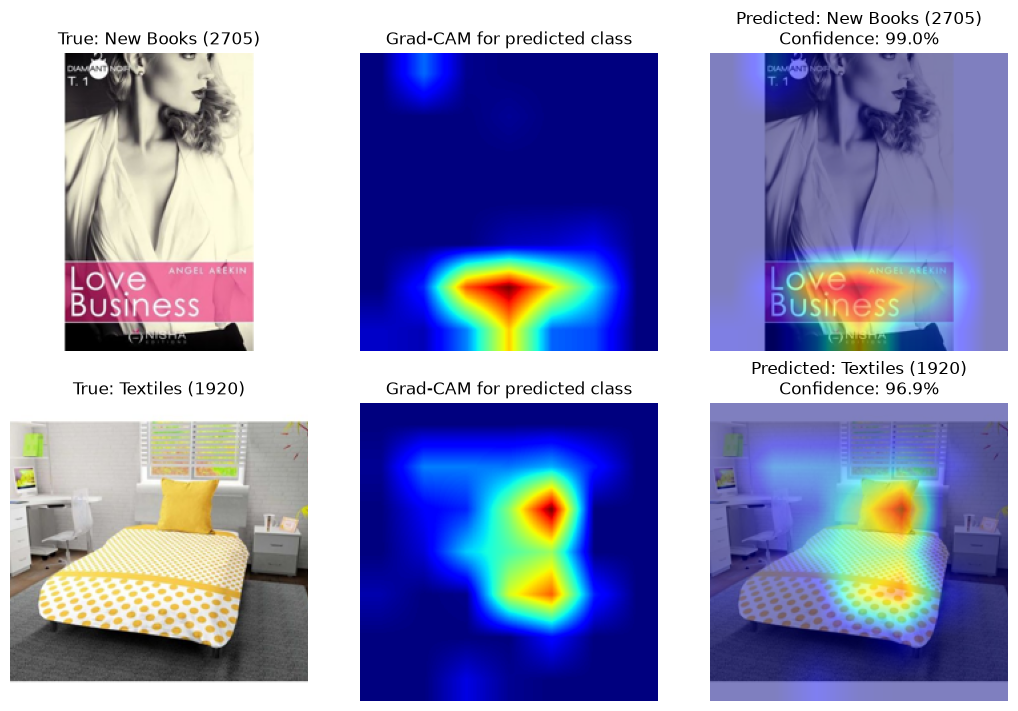

In [6]:
# Fixed, manually reviewed examples: book cover and home textiles.
SUCCESS_ROW_IDS  = [38611, 2315]
correct_examples = fixed_examples(SUCCESS_ROW_IDS)
assert all(
    predicted_code == int(row.prdtypecode)
    for row, predicted_code, _ in correct_examples
)

fig, axes = plt.subplots(2, 3, figsize=(10.5, 7), constrained_layout=True)

for row_index, (row, predicted_code, confidence) in enumerate(correct_examples):
    result = explain_row(row)
    axes[row_index, 0].imshow(result['display_image'])
    axes[row_index, 0].set_title(
        f'True: {category_name(row.prdtypecode)} ({row.prdtypecode})'
    )
    axes[row_index, 1].imshow(result['cam'], cmap='jet', vmin=0, vmax=1)
    axes[row_index, 1].set_title('Grad-CAM for predicted class')
    axes[row_index, 2].imshow(result['overlay'])
    axes[row_index, 2].set_title(
        f'Predicted: {category_name(predicted_code)} ({predicted_code})\n'
        f'Confidence: {confidence:.1%}'
    )
    for axis in axes[row_index]:
        axis.axis('off')

plt.show()

**Interpretation:** These selected examples show whether the strongest positive attribution lies on
product-specific regions rather than empty background. They illustrate individual predictions and
should not be interpreted as a quantitative result for the complete class.

## 5. Interpret two misclassifications

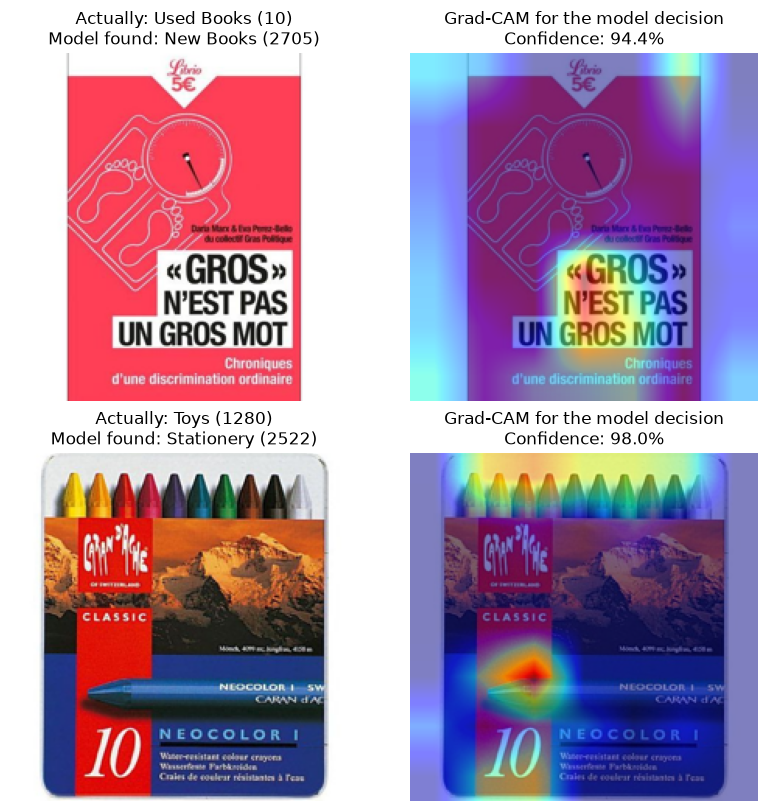

In [7]:
# Fixed errors: product condition and overlapping toy/stationery taxonomy.
ERROR_ROW_IDS  = [6602, 84339]
error_examples = fixed_examples(ERROR_ROW_IDS)
assert all(
    predicted_code != int(row.prdtypecode)
    for row, predicted_code, _ in error_examples
)

fig, axes = plt.subplots(2, 2, figsize=(8, 8), constrained_layout=True)

for row_index, (row, predicted_code, confidence) in enumerate(error_examples):
    predicted_explanation = explain_row(row)

    axes[row_index, 0].imshow(predicted_explanation['display_image'])
    axes[row_index, 0].set_title(
        f'Actually: {category_name(row.prdtypecode)} ({row.prdtypecode})\n'
        f'Model found: {category_name(predicted_code)} ({predicted_code})'
    )
    axes[row_index, 1].imshow(predicted_explanation['overlay'])
    axes[row_index, 1].set_title(
        f'Grad-CAM for the model decision\nConfidence: {confidence:.1%}'
    )
    for axis in axes[row_index]:
        axis.axis('off')

plt.show()

**Interpretation:** For the book, Grad-CAM highlights the printed title and typical cover layout.
These cues help the model recognize a book, but the image does not reliably show whether it is new
or used. For the crayon set, the model focuses on the crayons and their packaging but predicts
stationery/office supplies instead of toys. This is understandable because crayons can represent
both creative play and school or office supplies. The errors therefore reflect missing information
and overlapping catalog categories rather than attention to empty background.

## 6. Interpret the effect of smart white-border cropping

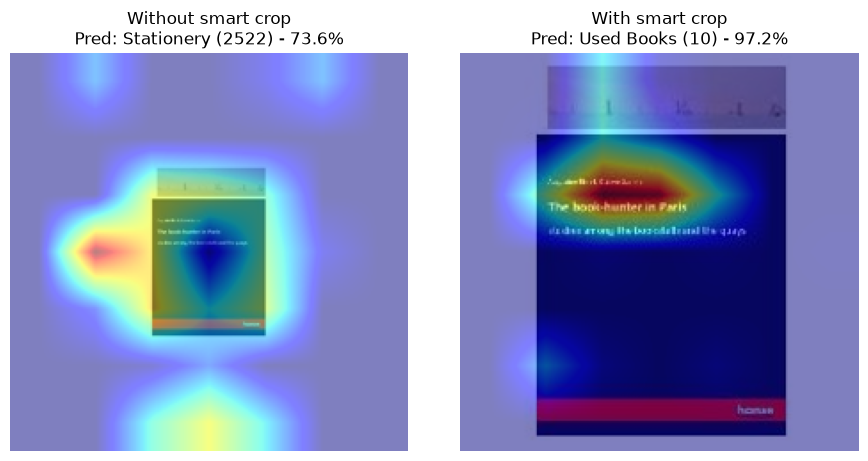

True class       : 10 Used Books
Without crop     : 2522 73.6%
With smart crop  : 10 97.2%


In [8]:
# Controlled comparison: same validation image, only preprocessing changes.
CROP_ROW_ID = 21859
crop_row = next(
    validation.loc[validation['row_id'].eq(CROP_ROW_ID)].itertuples(index=False)
)

plain_result = explain_row(
    crop_row,
    tensor_transform=plain_tensor_transform,
    display_transform=plain_display_transform,
)
smart_result = explain_row(crop_row)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)
axes[0].imshow(plain_result['overlay'])
axes[0].set_title(
    'Without smart crop\n'
    f"Pred: {category_name(plain_result['predicted_code'])} "
    f"({plain_result['predicted_code']}) - {plain_result['confidence']:.1%}"
)
axes[1].imshow(smart_result['overlay'])
axes[1].set_title(
    'With smart crop\n'
    f"Pred: {category_name(smart_result['predicted_code'])} "
    f"({smart_result['predicted_code']}) - {smart_result['confidence']:.1%}"
)
for axis in axes:
    axis.axis('off')
plt.show()

print('True class       :', int(crop_row.prdtypecode), category_name(crop_row.prdtypecode))
print('Without crop     :', plain_result['predicted_code'], f"{plain_result['confidence']:.1%}")
print('With smart crop  :', smart_result['predicted_code'], f"{smart_result['confidence']:.1%}")
assert plain_result['predicted_code'] != int(crop_row.prdtypecode)
assert smart_result['predicted_code'] == int(crop_row.prdtypecode)

**Interpretation:** This controlled example keeps resizing and normalization unchanged and varies
only the white-border crop. Without cropping, the book occupies a small part of the input and much of
the frame contains empty background; the model predicts stationery. Cropping removes most of this
background, enlarges the cover and makes its title and book-like typography more prominent. The Grad-CAM
activation consequently concentrates on the title region, and the prediction changes to the correct used-
book class. This suggests that the enlarged cover layout and typographic cues support the decision; it does
not demonstrate that the network reads the text like OCR or that cropping improves all validation images.

## 7. Conclusions for the image-interpretability requirement

For the selected products, Grad-CAM can reveal whether positive evidence is concentrated on the
product, its packaging or an unrelated region. This makes the image branch easier to audit and can
help identify preprocessing problems or visually ambiguous categories.

In a catalog workflow, these explanations can support model review and targeted error analysis.
They should not be shown as a guarantee that an individual prediction is correct; low-confidence
or business-critical cases still require appropriate validation or human review.

## 8. Limitations

- Grad-CAM is a coarse, qualitative attribution method and does not prove causality.
- The final feature stage has low spatial resolution, so small details may be blurred.
- The displayed products are selected examples, not a statistical sample of every failure mode.
- Attributions can change with preprocessing and the chosen target layer.
- The checkpoint attribution explains a single model view; it does not directly explain the final
  test-time-augmentation average reported elsewhere.

In [9]:
gradcam.close()
print('Grad-CAM hooks removed.')

Grad-CAM hooks removed.
